### Support Vector Machine — Does This Patient Have Heart Disease?

A **Support Vector Machine (SVM)** separates two classes by drawing the dividing line that leaves the **widest empty street** between them. The points on the edge of that street — the **support vectors** — are the only ones that shape the line.

Here we'll use the classic **Cleveland Heart Disease** dataset: predict whether a patient has heart disease from 13 clinical measurements (age, blood pressure, cholesterol, ECG results, and so on).

If you also worked through the **credit-default** notebook, watch the difference: there the classes were badly imbalanced (78/22) and the model missed most defaulters. Here the classes are **nearly balanced (~54/46)** — and you'll see how much healthier the recall looks as a result.

### What the columns mean

All 13 features are clinical measurements. Several are **codes, not quantities**:

- `age` — age in years
- `sex` — **1 = male, 0 = female**
- `cp` — chest pain type: **1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic**
- `trestbps` — resting blood pressure (mm Hg)
- `chol` — serum cholesterol (mg/dl)
- `fbs` — fasting blood sugar > 120 mg/dl (**1 = true, 0 = false**)
- `restecg` — resting ECG: **0 = normal, 1 = ST-T abnormality, 2 = left-ventricular hypertrophy**
- `thalach` — maximum heart rate achieved
- `exang` — exercise-induced angina (**1 = yes, 0 = no**)
- `oldpeak` — ST depression induced by exercise
- `slope` — slope of the peak exercise ST segment: **1 = upsloping, 2 = flat, 3 = downsloping**
- `ca` — number of major vessels (0–3) colored by fluoroscopy
- `thal` — **3 = normal, 6 = fixed defect, 7 = reversible defect**
- `num` — **the raw diagnosis: 0 = no disease, 1–4 = increasing severity of disease**

In [1]:
import os
print(os.getcwd())

C:\Users\Shaik\ML-Foundations\Classification\SVM(SupportVectorMachine)


In [2]:
import pandas as pd

In [3]:
df= pd.read_csv("../../Datasets/heart_disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:

df['thal'].unique()

array(['6.0', '3.0', '7.0', '?'], dtype=object)

In [5]:
df= pd.read_csv("../../Datasets/heart_disease.csv", na_values= '?')
print('rows, columns:', df.shape)
df.head()

rows, columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
#we have some null_values
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [7]:
df.shape

(303, 14)

In [8]:
#we are droping null_values compare to number rows it is not that big of a deal
df= df.dropna()
df.shape

(297, 14)

In [9]:
df.num.value_counts()

num
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

In [10]:
##num column containes whether have any isuues to have issue 0-6, fo rthis sake of this we are gointo do if > 0 consider as patient

#first (df['num']>0) thsi makes True or False then .astype(int) makes it into 0 or 1 True= 1. False= 0

df['target']= (df['num']>0).astype(int)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


In [11]:
df['target'].unique()

array([0, 1])

In [12]:
df['num'].unique()

array([0, 2, 1, 3, 4], dtype=int64)

In [13]:
#StandardScaling

from sklearn.preprocessing import StandardScaler

X= df.drop(columns= ['num', 'target'])
y= df['target']

#initilizing StandardScaler
Scaler= StandardScaler()

X_scaled= Scaler.fit_transform(X)
X_scaled[:5]

array([[ 0.93618065,  0.69109474, -2.24062879,  0.75038004, -0.27644339,
         2.43042728,  1.01019851,  0.01749443, -0.69641941,  1.06896529,
         2.26414539, -0.72197605,  0.65587737],
       [ 1.3789285 ,  0.69109474,  0.87388018,  1.59626645,  0.74455507,
        -0.41145029,  1.01019851, -1.81633388,  1.43591632,  0.38177332,
         0.6437811 ,  2.47842525, -0.89422007],
       [ 1.3789285 ,  0.69109474,  0.87388018, -0.65943064, -0.35349988,
        -0.41145029,  1.01019851, -0.89941972,  1.43591632,  1.32666228,
         0.6437811 ,  1.41162482,  1.17257652],
       [-1.94168041,  0.69109474, -0.16428947, -0.09550637,  0.05104668,
        -0.41145029, -1.00341866,  1.63300986, -0.69641941,  2.09975324,
         2.26414539, -0.72197605, -0.89422007],
       [-1.49893255, -1.44697961, -1.20245913, -0.09550637, -0.83510292,
        -0.41145029,  1.01019851,  0.97807117, -0.69641941,  0.29587432,
        -0.97658319, -0.72197605, -0.89422007]])

In [14]:
#spliting the data train_test_split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split (X_scaled, y, test_size= 0.2, stratify= y, random_state= 42)


In [15]:
print("Training_Data:", X_train.shape[0])
print("Test_Data:", X_test.shape[0])


Training_Data: 237
Test_Data: 60


In [16]:
#training our model

from sklearn.svm import SVC

model= SVC(kernel= 'rbf')

model.fit(X_train, y_train)

SVC()

In [17]:
#classification report

from sklearn.metrics import classification_report

y_pred= model.predict(X_test)

print(classification_report(y_test, y_pred, target_names= ['no disease(0)', 'disease(0)']))

               precision    recall  f1-score   support

no disease(0)       0.83      0.91      0.87        32
   disease(0)       0.88      0.79      0.83        28

     accuracy                           0.85        60
    macro avg       0.85      0.85      0.85        60
 weighted avg       0.85      0.85      0.85        60



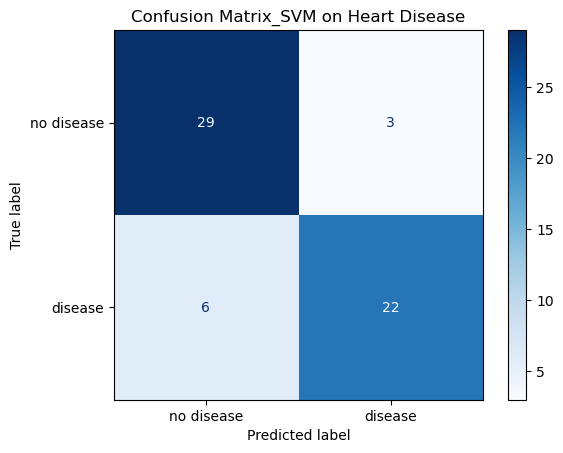

In [22]:
#display confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm= confusion_matrix(y_test, y_pred)

disp= ConfusionMatrixDisplay(confusion_matrix= cm, display_labels=['no disease', 'disease'])
disp.plot(cmap= 'Blues')
plt.title("Confusion Matrix_SVM on Heart Disease")
plt.show()